# Simulation of an Engineering Signal Under Measurement Uncertainty

# Day 1 — NumPy + Stochastic Simulation

## Simulation of an Engineering Signal Under Measurement Uncertainty

**Objective:** Build a deterministic dynamic engineering signal, introduce measurement uncertainty, and use statistical analysis and Monte Carlo simulation to investigate how uncertainty affects observations.

**Research question:** How does increasing measurement uncertainty affect the distribution of observations of a dynamic engineering system?

### Model

The underlying signal is

$$
x(t)=e^{-0.15t}\sin(2\pi(0.5)t), \qquad 0\leq t\leq 20.
$$
The measurement model is

$$
y(t)=x(t)+\epsilon(t),
$$

where the measurement error is modelled as independent Gaussian noise:

$$
\epsilon(t)\sim\mathcal{N}(0,\sigma^2).
$$

Here, $x(t)$ is the true signal in the model, $y(t)$ is the measured signal, and $\sigma$ is the noise standard deviation.

### Investigation workflow

Model → Observe → Quantify → Perturb → Repeat → Analyse → Interpret → Generalise.

**Reproducibility:** Random simulations use NumPy's `default_rng` with explicit seeds so the results can be reproduced.

## Imports and shared setup

Import the libraries used throughout the notebook. NumPy handles numerical arrays and random simulation; Matplotlib is used to visualise the signal and uncertainty.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Use a consistent plotting default.
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True

# Task 1 — Deterministic signal

## Purpose

Create the underlying signal before introducing measurement uncertainty.

The time interval is $[0,20]$, represented by 1,000 evenly spaced samples. The exponential factor produces decay, while the sine function produces oscillation.

$$
x(t)=e^{-0.15t}\sin(\pi t)
$$

because $2\pi(0.5)=\pi$.

In [4]:
t = np.linspace(0, 20, 1000)

x = np.exp(-0.5 * t) * np.sin(2 * np.pi * 0.5 * t)

print("t shape:", t.shape)
print("x shape:", x.shape)
print("First 5 time values:", t[:5])
print("First 5 signal values:", x[:5])

assert t.shape == (1000,)
assert x.shape == (1000,)

t shape: (1000,)
x shape: (1000,)
First 5 time values: [0.         0.02002002 0.04004004 0.06006006 0.08008008]
First 5 signal values: [0.         0.06222727 0.12297133 0.18201775 0.23916315]


### Task 1 — Visual inspection

Plot the deterministic signal. Before running the cell, predict what you expect the oscillation amplitude to do over time.

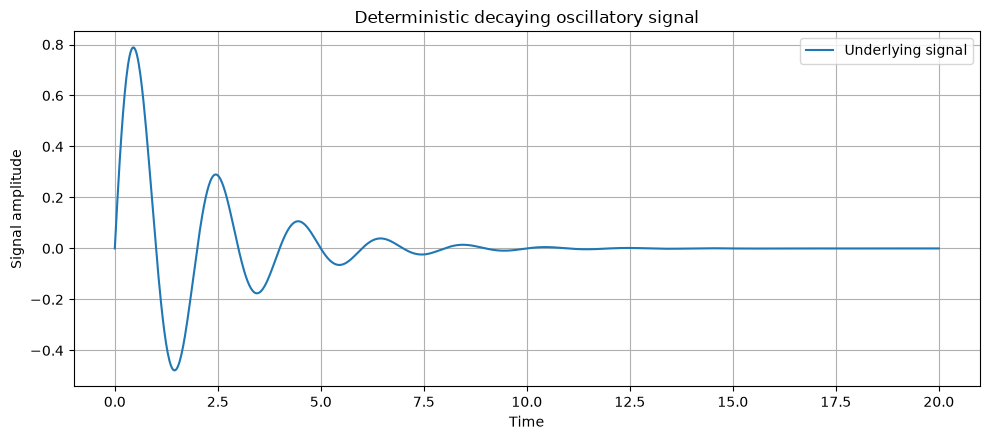

In [12]:
plt.figure()
plt.plot(t, x, label="Underlying signal")
plt.xlabel("Time")
plt.ylabel("Signal amplitude")
plt.title("Deterministic decaying oscillatory signal")
plt.legend()
plt.tight_layout()
plt.show()

### Task 1 — Interpretation

The time vector contains 1,000 samples over the interval from 0 to 20. The signal oscillates because of the sine term, while the exponential multiplier reduces the oscillation amplitude as time increases.

This is a simplified mathematical model of a decaying oscillatory response. It is not intended to represent a particular physical device without further parameter identification.

# Exercise 2 — Add measurement uncertainty

## Purpose

Represent imperfect measurement by adding Gaussian noise to the underlying signal.
$$
[
y(t)=x(t)+\epsilon(t),\qquad \epsilon(t)\sim\mathcal{N}(0,\sigma^2).
]
$$
Use $(\sigma=0.05)$ for this exercise. The random-number generator is initialised with a fixed seed so that the same noise sequence is produced when the cell is rerun.

In [26]:
rng = np.random.default_rng(42)

sigma = 0.05

noise = rng.normal(
    loc=0.0,
    scale=sigma,
    size=t.shape
)

y = x + noise

print("Noise shape:", noise.shape)
print("Measured signal shape:", y.shape)
print("first 5 noise values:", noise[:5])
print("First 5 measurements:", y[:5])

assert noise.shape == x.shape
assert y.shape == x.shape

Noise shape: (1000,)
Measured signal shape: (1000,)
first 5 noise values: [ 0.01523585 -0.05199921  0.03752256  0.04702824 -0.09755176]
First 5 measurements: [0.01523585 0.01022806 0.16049389 0.22904599 0.14161139]


### Exercise 2 — Compare true and measured signals

The measurement will not generally lie exactly on the underlying signal. Plot both so the effect of noise can be seen.

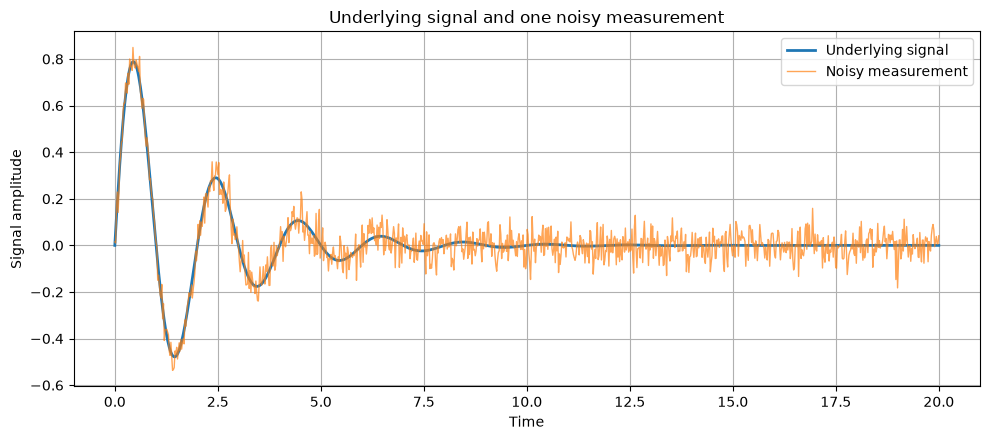

In [20]:
plt.figure()
plt.plot(t, x, label="Underlying signal", linewidth=2)
plt.plot(t, y, label="Noisy measurement", alpha=0.7, linewidth=1)
plt.xlabel("Time")
plt.ylabel("Signal amplitude")
plt.title("Underlying signal and one noisy measurement")
plt.legend()
plt.tight_layout()
plt.show()

### Task 2 — Interpretation

The noisy measurement differs from the underlying signal because a random error term has been added at each sample. A fixed seed supports reproducibility; it does not make the noise less random in its statistical interpretation.

The model assumes that the noise has zero expected value and constant standard deviation, and that errors at different samples are independent. Real measurement systems may have bias, correlated noise, drift, quantisation, or state-dependent uncertainty.

# Task 3 — Quantify uncertainty

## Purpose

Summarise the realised noise using descriptive statistics and compare its empirical standard deviation with the theoretical value $(\sigma=0.05\$.

The empirical mean and standard deviation will not usually equal their theoretical values exactly because this is a finite random sample.

In [25]:
noise_mean = np.mean(noise)
noise_std = np.std(noise)
noise_min = np.min(noise)
noise_max = np.max(noise)
noise_p5 = np.percentile(noise, 5)
noise_p95 = np.percentile(noise, 95)

print(f"Mean: {noise_min:.6f}")
print(f"Standard deviation: {noise_std:.6f}")
print(f"Minimum: {noise_min:.6f}")
print(f"Maximum: {noise_max:.6f}")
print(f"5th percentile: {noise_p5:.6f}")
print(f"95th percentile: {noise_p95:.6f}")
print(f"Empirical standard deviation: {noise_std:.6f}")


Mean: -0.182421
Standard deviation: 0.049436
Minimum: -0.182421
Maximum: 0.158943
5th percentile: -0.084282
95th percentile: 0.080812
Empirical standard deviation: 0.049436


### Task 3 — Interpretation

- The **mean** indicates the average realised noise level. For zero-mean noise, it should be near zero over a sufficiently large sample.
- The **standard deviation** measures the spread of noise around its mean.
- The **minimum and maximum** are the most extreme values in this particular sample; they are not fixed theoretical limits for a Gaussian distribution.
- The **5th and 95th percentiles** mark the lower and upper ends of a central 90% interval for the realised noise values.

The empirical standard deviation is an estimate of the theoretical value. It differs because only a finite number of random samples were generated.

# Exercise 4 — Vary the uncertainty level

## Purpose

Compare the empirical standard deviation of Gaussian noise for \$\sigma\in\{0.01,0.05,0.10,0.20\}\$.

To make the comparison controlled, generate one standard-normal array and scale the same draws by each value of $\sigma$. This uses common random numbers: the noise patterns correspond across conditions while their magnitudes change.

In [31]:
sigma_values = np.array([0.01, 0.05, 0.10, 0.20])

rng = np.random.default_rng(2026)
standard_noise = rng.normal(loc=0.0, scale=1.0, size=t.shape)

empirical_std = []

for sigma_level in sigma_values:
    noise_at_level = sigma_level * standard_noise
    empirical_std.append(np.std(noise_at_level, ddof=0))

empirical_std = np.array(empirical_std)

print("Theoretical standard deviations:", sigma_values)
print("Empirical standard deviations:", empirical_std)

for theoretical, empirical in zip(sigma_values, empirical_std):
    print(
        f"Theoretical: {theoretical:.3f} | "
        f"Empirical: {empirical:.5f}"
    )

Theoretical standard deviations: [0.01 0.05 0.1  0.2 ]
Empirical standard deviations: [0.01030456 0.05152278 0.10304556 0.20609112]
Theoretical: 0.010 | Empirical: 0.01030
Theoretical: 0.050 | Empirical: 0.05152
Theoretical: 0.100 | Empirical: 0.10305
Theoretical: 0.200 | Empirical: 0.20609
